# Credit Card Churn Analysis — Exploratory Data Analysis (EDA)

## Objectives

This notebook explores the reduced Credit Card Churn dataset created in the ETL notebook, `BankChurners_reduced.csv`.

The objectives are to:
- Describe the dataset and summarise its variables.
- Examine the distribution of the target variable, `Attrition_Flag`.
- Explore how customer characteristics, account details, financial measures and activity relate to attrition.
- Identify patterns, potential outliers, class imbalance and relationships between explanatory variables.
- Record questions and findings that can inform feature engineering and classification modelling.

The analysis is exploratory: associations do not establish that a variable causes customer attrition.

## Input

- `BankChurners_reduced.csv`, produced by `Credit_card_churn_ETL.ipynb`.

**Target-variable naming note:** the column in the dataset is `Attrition_Flag` (with an underscore). This notebook uses that exact column name.

---

# Change Working Directory

## Purpose

The ETL notebook uses a `Datasets` folder and changes the working directory before loading a CSV. The code below follows the same general approach. It assumes this notebook is saved in a subfolder one level below the project folder and that `Datasets` is in the project folder.

If your folder structure differs, adjust the path or set the working directory manually.

In [1]:
import os

current_dir = os.getcwd()
current_dir

'/Users/mariaoanacucu/Documents/VS Code Projects/Credit_card_churn_analysis/jupyter_notebooks'

In [2]:
print(os.listdir())

['Credit_card_churn_ETL.ipynb', '.DS_Store', 'Credit_card_churn_EDA_draft.ipynb', 'Notebook_Template.ipynb']


In [3]:
# Move to the project's Datasets folder (adjust if your folder structure differs)
os.chdir(os.path.join(os.path.dirname(os.getcwd()), 'Datasets'))
print("Current working directory:", os.getcwd())
print(os.listdir())

Current working directory: /Users/mariaoanacucu/Documents/VS Code Projects/Credit_card_churn_analysis/Datasets
['BankChurners_reduced.csv', 'BankChurners.csv']


---

## 1. Load Python libraries

Pandas and NumPy support data manipulation and numerical operations. Seaborn and Matplotlib are used to visualise distributions and relationships.

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

---

## 2. Load and inspect the reduced dataset

Load the reduced dataset created by the ETL notebook into a DataFrame called `df`.

In [5]:
df = pd.read_csv('BankChurners_reduced.csv')
df.head()

,Attrition_Flag,Customer_Age,Gender,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Total_Trans_Amt,Total_Trans_Ct,Credit_Limit,Total_Revolving_Bal,Avg_Utilization_Ratio
0,Existing Customer,45,M,High School,Married,$60K - $80K,Blue,39,5,1,3,1144,42,12691.0,777,0.061
1,Existing Customer,49,F,Graduate,Single,Less than $40K,Blue,44,6,1,2,1291,33,8256.0,864,0.105
2,Existing Customer,51,M,Graduate,Married,$80K - $120K,Blue,36,4,1,0,1887,20,3418.0,0,0.000
3,Existing Customer,40,F,High School,Unknown,Less than $40K,Blue,34,3,4,1,1171,20,3313.0,2517,0.760
4,Existing Customer,40,M,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,816,28,4716.0,0,0.000


### 2.1 Dimensions and structure

Check the number of records and variables, column names, and data types.

In [6]:
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (10127, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Attrition_Flag            10127 non-null  object 
 1   Customer_Age              10127 non-null  int64  
 2   Gender                    10127 non-null  object 
 3   Education_Level           10127 non-null  object 
 4   Marital_Status            10127 non-null  object 
 5   Income_Category           10127 non-null  object 
 6   Card_Category             10127 non-null  object 
 7   Months_on_book            10127 non-null  int64  
 8   Total_Relationship_Count  10127 non-null  int64  
 9   Months_Inactive_12_mon    10127 non-null  int64  
 10  Contacts_Count_12_mon     10127 non-null  int64  
 11  Total_Trans_Amt           10127 non-null  int64  
 12  Total_Trans_Ct            10127 non-null  int64  
 13  Credit_Limit              10127 no

In [7]:
df.dtypes

Attrition_Flag               object
Customer_Age                  int64
Gender                       object
Education_Level              object
Marital_Status               object
Income_Category              object
Card_Category                object
Months_on_book                int64
Total_Relationship_Count      int64
Months_Inactive_12_mon        int64
Contacts_Count_12_mon         int64
Total_Trans_Amt               int64
Total_Trans_Ct                int64
Credit_Limit                float64
Total_Revolving_Bal           int64
Avg_Utilization_Ratio       float64
dtype: object

### 2.2 Data quality checks

The ETL notebook reported no null values or exact duplicate rows in the original dataset, but we should verify these checks again on the reduced dataset. The value `Unknown` may occur in categorical columns and is not the same as a missing value.

In [8]:
# Missing values by column
df.isnull().sum()

Attrition_Flag              0
Customer_Age                0
Gender                      0
Education_Level             0
Marital_Status              0
Income_Category             0
Card_Category               0
Months_on_book              0
Total_Relationship_Count    0
Months_Inactive_12_mon      0
Contacts_Count_12_mon       0
Total_Trans_Amt             0
Total_Trans_Ct              0
Credit_Limit                0
Total_Revolving_Bal         0
Avg_Utilization_Ratio       0
dtype: int64

In [9]:
# Number of exact duplicate rows
df.duplicated().sum()

0

In [10]:
# Check for 'Unknown' categories in object columns
for col in df.select_dtypes(include='object').columns:
    print(f"{col}: {(df[col].astype(str).str.strip().str.lower() == 'unknown').sum()} 'Unknown' values")

Attrition_Flag: 0 'Unknown' values
Gender: 0 'Unknown' values
Education_Level: 1519 'Unknown' values
Marital_Status: 749 'Unknown' values
Income_Category: 1112 'Unknown' values
Card_Category: 0 'Unknown' values


**Findings — `Unknown` values**

The reduced dataset contains `Unknown` entries in three categorical variables:

- `Education_Level`: 1,519 records (15.0%).
- `Marital_Status`: 749 records (7.4%).
- `Income_Category`: 1,112 records (11.0%).

No `Unknown` values appear in `Gender`, `Card_Category` or `Attrition_Flag`. These entries are category labels rather than pandas null values, so the earlier missing-value check does not count them as missing.

**Implications:** `Unknown` represents a meaningful data-quality consideration: the value is present, but the underlying education, marital-status or income information is not specified. We should not automatically replace these records or treat `Unknown` as a genuine education, marital-status or income group. For EDA, retain and report the category so that these records are not silently discarded. Before modelling, compare how the category behaves and choose a documented treatment (for example, retaining it as an explicit category or testing a suitable alternative). The values alone do not tell us why the information is unknown.

---

## 3. Descriptive statistics

### 3.1 Numerical variables

The summary below reports count, mean, standard deviation, minimum, quartiles and maximum for numerical variables. These statistics help reveal scale differences, skewness and possible extreme values.

In [11]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,10127.0,46.325960,8.016814,26.0,41.000,46.000,52.000,73.000
Months_on_book,10127.0,35.928409,7.986416,13.0,31.000,36.000,40.000,56.000
Total_Relationship_Count,10127.0,3.812580,1.554408,1.0,3.000,4.000,5.000,6.000
Months_Inactive_12_mon,10127.0,2.341167,1.010622,0.0,2.000,2.000,3.000,6.000
Contacts_Count_12_mon,10127.0,2.455317,1.106225,0.0,2.000,2.000,3.000,6.000
Total_Trans_Amt,10127.0,4404.086304,3397.129254,510.0,2155.500,3899.000,4741.000,18484.000
Total_Trans_Ct,10127.0,64.858695,23.472570,10.0,45.000,67.000,81.000,139.000
Credit_Limit,10127.0,8631.953698,9088.776650,1438.3,2555.000,4549.000,11067.500,34516.000
Total_Revolving_Bal,10127.0,1162.814061,814.987335,0.0,359.000,1276.000,1784.000,2517.000
Avg_Utilization_Ratio,10127.0,0.274894,0.275691,0.0,0.023,0.176,0.503,0.999


### 3.2 Categorical variables

For categorical variables, inspect the number of distinct values and the most frequent category. Frequency tables provide more detail for individual columns.

In [12]:
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

df[categorical_cols].describe().T

,count,unique,top,freq
Attrition_Flag,10127,2,Existing Customer,8500
Gender,10127,2,F,5358
Education_Level,10127,7,Graduate,3128
Marital_Status,10127,4,Married,4687
Income_Category,10127,6,Less than $40K,3561
Card_Category,10127,4,Blue,9436


In [13]:
for col in categorical_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts(dropna=False).to_frame(name='Count'))


--- Attrition_Flag ---


,Count
Attrition_Flag,
Existing Customer,8500
Attrited Customer,1627



--- Gender ---


,Count
Gender,
F,5358
M,4769



--- Education_Level ---


...

,Count
Marital_Status,
Married,4687
Single,3943
Unknown,749
Divorced,748



--- Income_Category ---


,Count
Income_Category,
Less than $40K,3561
$40K - $60K,1790
$80K - $120K,1535
$60K - $80K,1402
Unknown,1112
$120K +,727



--- Card_Category ---


,Count
Card_Category,
Blue,9436
Silver,555
Gold,116
Platinum,20


### 3.3 Target variable: customer attrition

The target column is `Attrition_Flag`. First inspect the number of customers in each class and the proportion represented by each class. This shows whether the target is imbalanced, which matters when evaluating classification models.

In [14]:
target = 'Attrition_Flag'

if target not in df.columns:
    raise KeyError(f"Expected target column {target!r} was not found. Check df.columns.")

display(df[target].value_counts(dropna=False).to_frame(name='Count'))
display((df[target].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame(name='Percentage'))

,Count
Attrition_Flag,
Existing Customer,8500
Attrited Customer,1627


,Percentage
Attrition_Flag,
Existing Customer,83.93
Attrited Customer,16.07


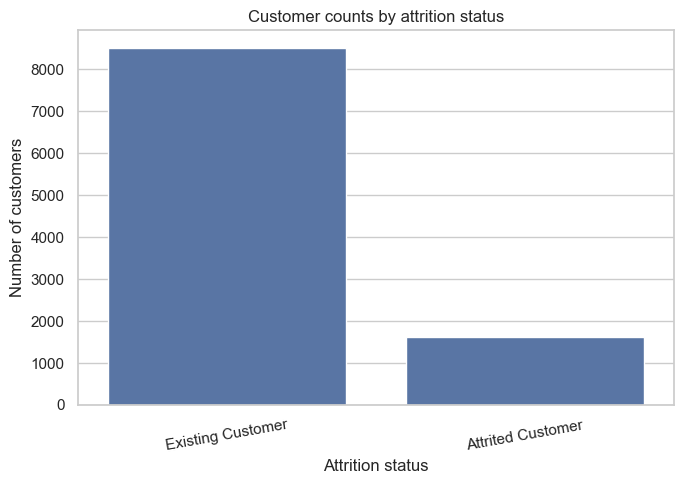

In [16]:
plt.figure(figsize=(7, 5))
order = df[target].value_counts().index
ax = sns.countplot(data=df, x=target, order=order)
ax.set(title='Customer counts by attrition status', xlabel='Attrition status', ylabel='Number of customers')
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

**Interpretation prompt:** Is one class much more common than the other? If so, accuracy alone may be misleading when evaluating a classifier. Later modelling should consider metrics such as precision, recall, F1-score and the confusion matrix.

### Section 3 summary

The dataset contains **10,127 customers and 16 variables**, including 10 numerical variables and 6 categorical variables. Numerical variables vary considerably in scale: for example, `Customer_Age` ranges from 26 to 73 years, `Total_Trans_Amt` ranges from 510 to 18,484, and `Avg_Utilization_Ratio` ranges from 0.0 to 1.0. The categorical frequency tables show that `Blue` is by far the most common card category, while `Education_Level`, `Marital_Status` and `Income_Category` include `Unknown` entries.

The target is imbalanced: **8,500 customers (83.9%) are labelled `Existing Customer`, compared with 1,627 (16.1%) labelled `Attrited Customer`**. This is not an unusually small dataset in absolute terms, and 1,627 attrited examples provide useful data for modelling. However, the minority class is substantially smaller, so a classifier could favour the majority class and still report apparently high accuracy. This is a modelling consideration rather than a reason to abandon the dataset. When evaluating models, compare class-specific precision and recall, F1-score, a confusion matrix and balanced metrics rather than relying on accuracy alone. Use a stratified train/test split so that both subsets retain a similar target distribution. The final model's usefulness will depend on its performance on held-out data, not dataset size alone.

---

## 4. Univariate analysis: distributions of numerical variables

Histograms show the shape of each numerical distribution. Reviewing them can help identify skewness, unusual values and variables that may benefit from transformation. These plots are descriptive rather than automatic grounds for removing observations.

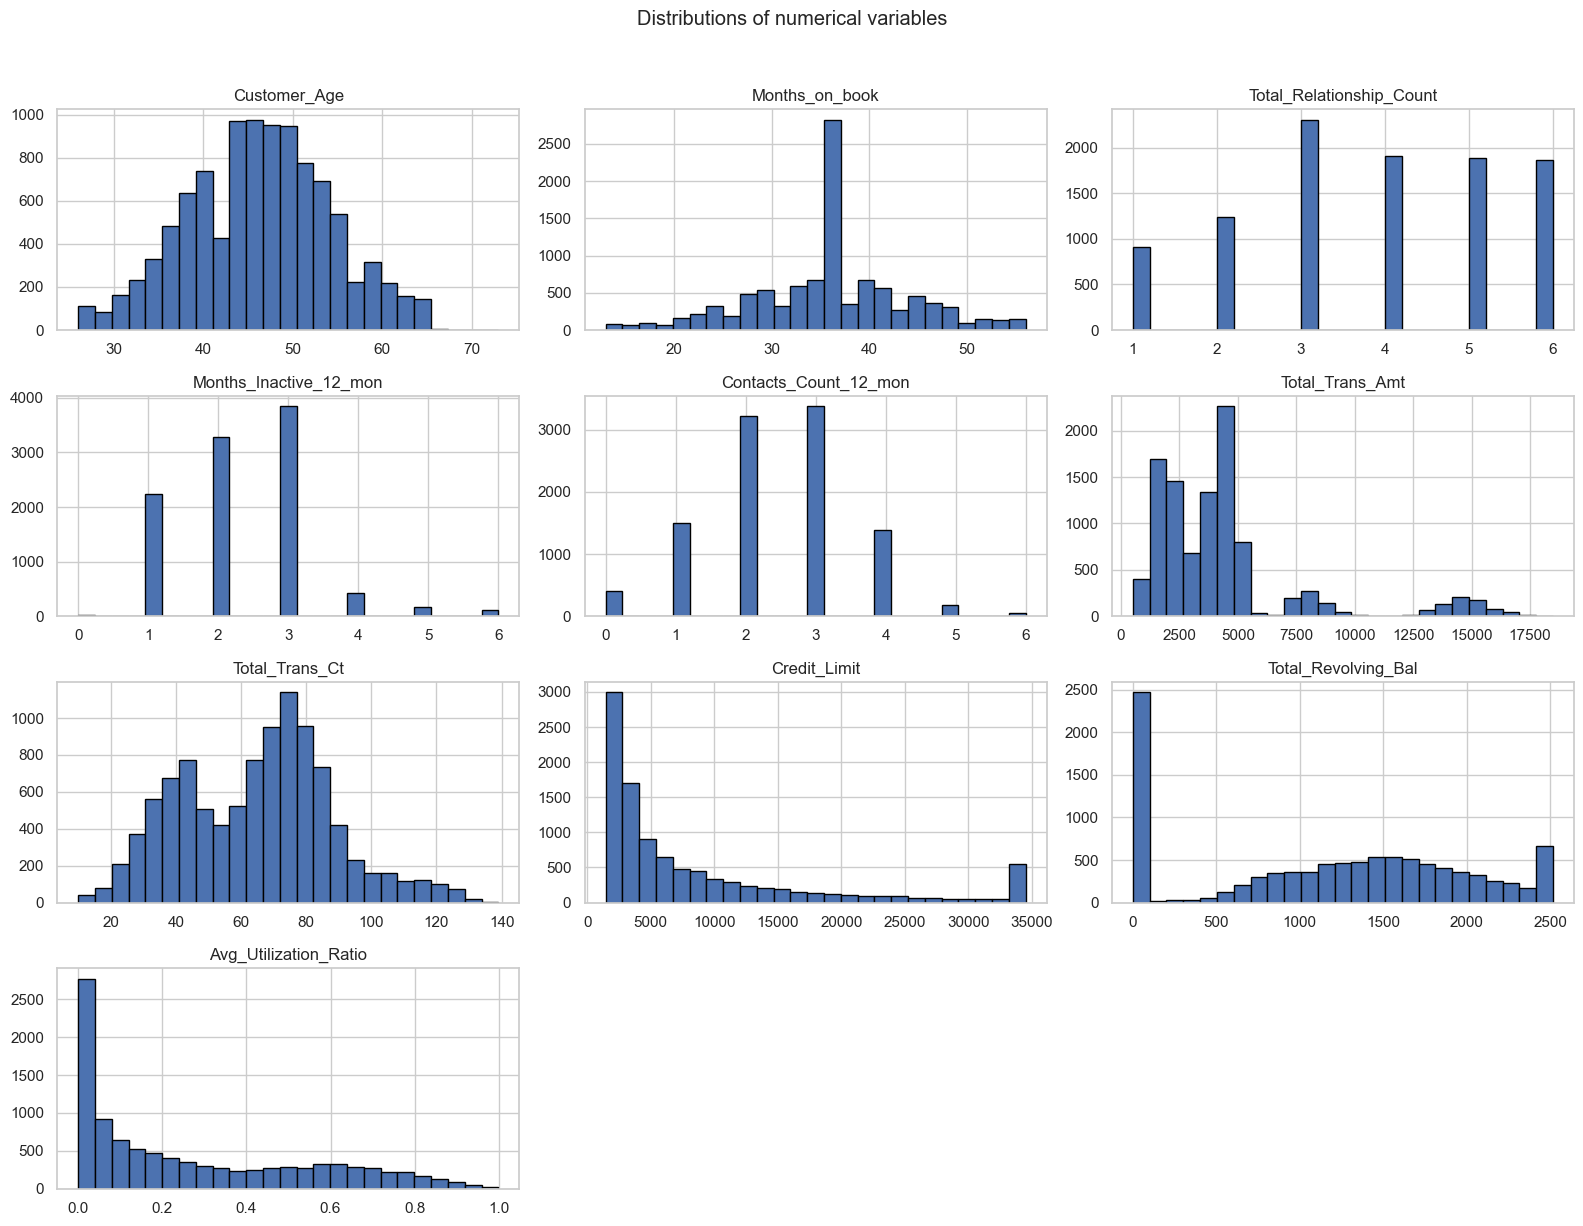

In [17]:
# Histograms for all numerical variables
df[numeric_cols].hist(bins=25, figsize=(16, 12), edgecolor='black')
plt.suptitle('Distributions of numerical variables', y=1.02)
plt.tight_layout()
plt.show()

### 4.1 Boxplots by attrition status

Boxplots help compare the distributions and spread of numerical variables across the two target classes. Variables with very different scales are plotted separately to keep the comparisons readable.

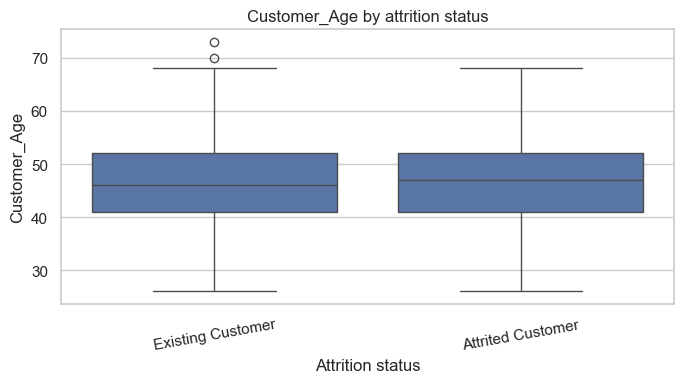

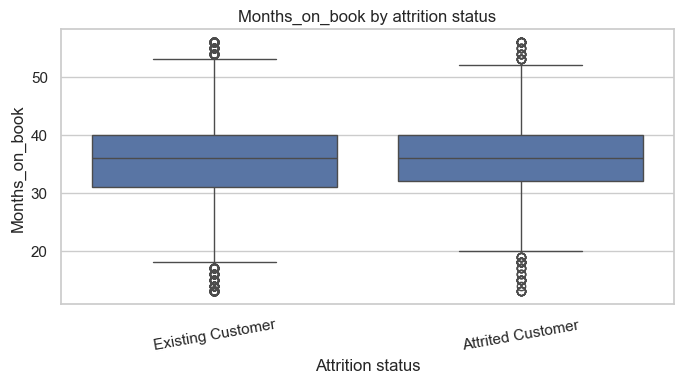

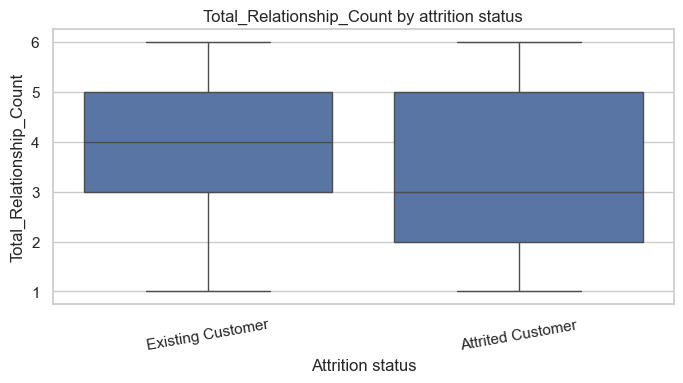

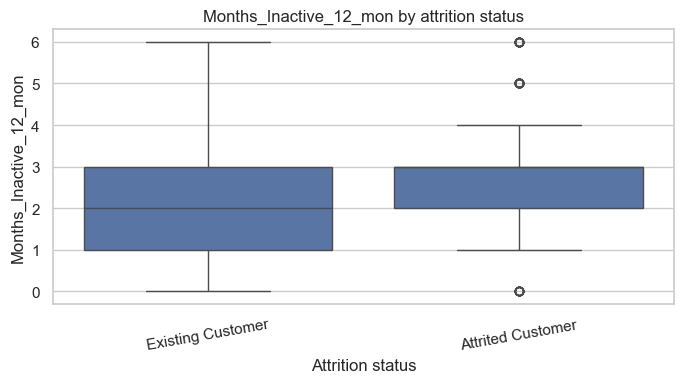

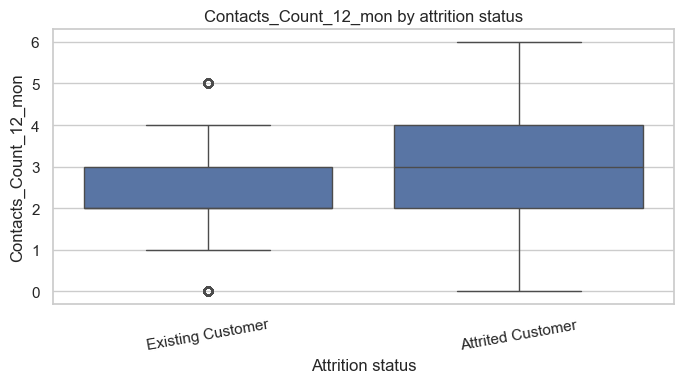

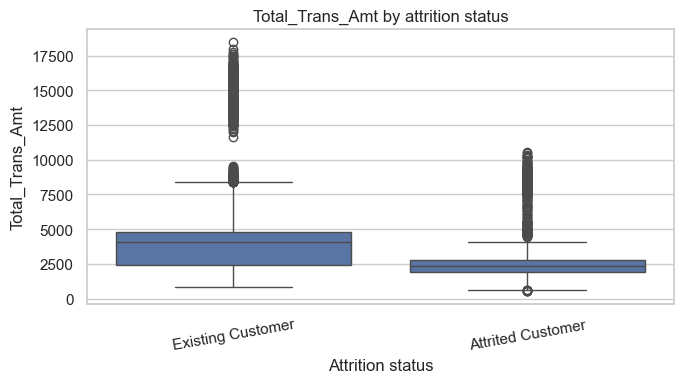

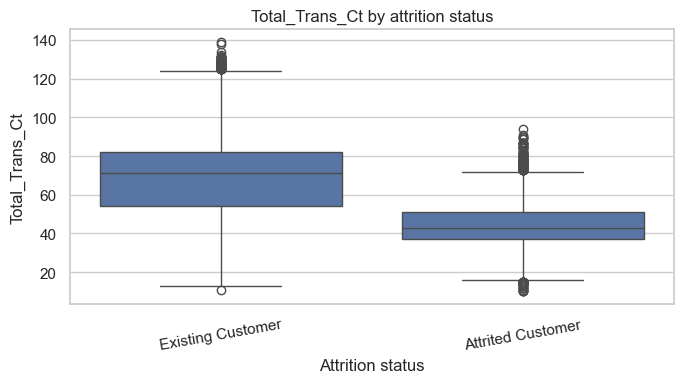

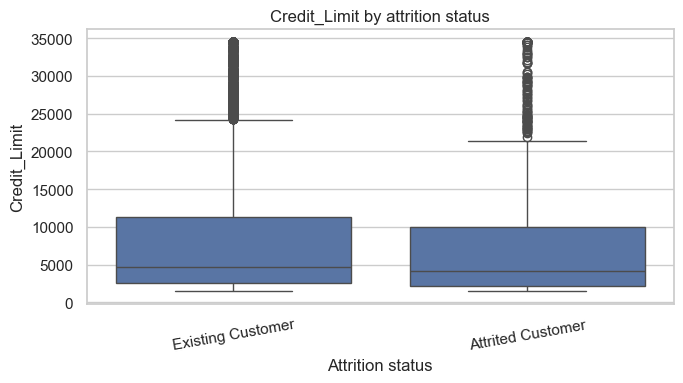

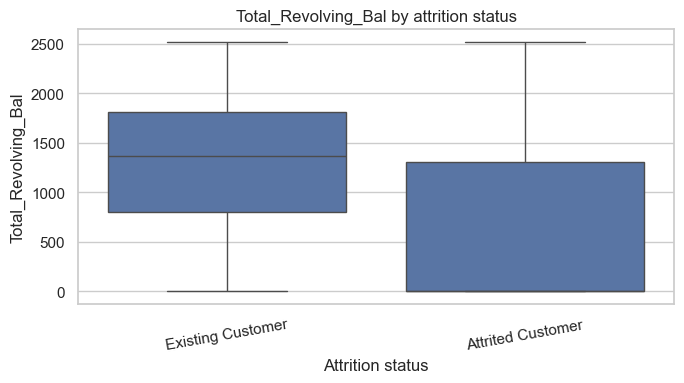

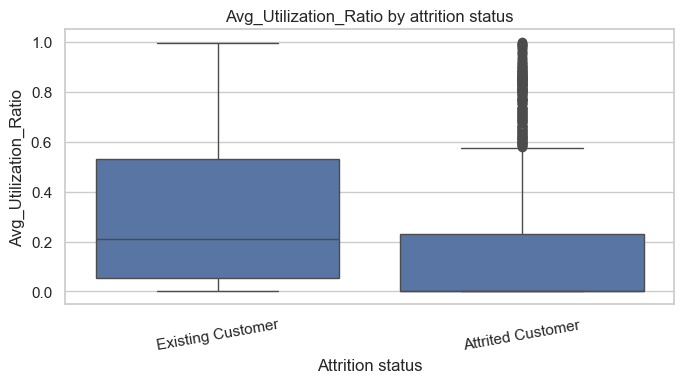

In [18]:
for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=target, y=col)
    plt.title(f'{col} by attrition status')
    plt.xlabel('Attrition status')
    plt.ylabel(col)
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.show()

### Section 4 summary

**Histograms.** The numerical variables have different shapes and scales. `Customer_Age` and `Months_on_book` are comparatively concentrated around their middle values, whereas `Total_Trans_Amt` and `Credit_Limit` have wide ranges and visibly right-skewed distributions. `Total_Trans_Ct`, relationship counts, inactivity months and contact counts are discrete counts, so their values form distinct peaks rather than smooth continuous distributions. `Avg_Utilization_Ratio` is bounded between 0 and 1 and includes many low values. These patterns support checking skew and scale during later modelling, but do not by themselves justify removing observations or transforming variables.

**Boxplots.** Comparing numerical variables by attrition status suggests clearer group differences for transaction behaviour and customer activity than for age or tenure. Attrited customers have lower median `Total_Trans_Amt` and `Total_Trans_Ct`, lower `Total_Revolving_Bal` and `Avg_Utilization_Ratio`, and somewhat higher `Months_Inactive_12_mon` and `Contacts_Count_12_mon`. Their median `Total_Relationship_Count` is also lower. By contrast, age and months on the books appear similar across the two groups. The plots can flag potentially useful predictors, but overlapping distributions mean no single variable perfectly separates the classes; boxplot outliers should be investigated in context rather than automatically removed.

---

## 5. Relationships with the target variable

The following analyses focus on how variables differ between existing and attrited customers. Differences may indicate useful predictive signals, but they do not prove that the variables cause attrition.

### 5.1 Numerical variables: compare group summaries

Compare the mean and median of each numerical variable by attrition status. Medians can be useful where distributions are skewed or contain extreme values.

In [19]:
group_summary = df.groupby(target)[numeric_cols].agg(['mean', 'median']).round(2)
group_summary

Customer_Age        Months_on_book         \
                          mean median           mean median   
Attrition_Flag                                                
Attrited Customer        46.66   47.0          36.18   36.0   
Existing Customer        46.26   46.0          35.88   36.0   

                  Total_Relationship_Count        Months_Inactive_12_mon  \
                                      mean median                   mean   
Attrition_Flag                                                             
Attrited Customer                     3.28    3.0                   2.69   
Existing Customer                     3.91    4.0                   2.27   

                         Contacts_Count_12_mon        Total_Trans_Amt          \
                  median                  mean median            mean  median   
Attrition_Flag                                                                  
Attrited Customer    3.0                  2.97    3.0         3095.03  2329.0   
Existing Customer    2.0                  2.36    2.0         4654.66  4100.0   

                  Total_Trans_Ct        Credit_Limit          \
                            mean median         mean  median   
Attrition_Flag                                                 
Attrited Customer          44.93   43.0      8136.04  4178.0   
Existing Customer          68.67   71.0      8726.88  4643.5   

                  Total_Revolving_Bal         Avg_Utilization_Ratio         
                                 mean  median                  mean median  
Attrition_Flag                                                              
Attrited Customer              672.82     0.0                  0.16   0.00  
Existing Customer             1256.60  1364.0                  0.30   0.21

**Summary — numerical group comparisons**

The clearest differences are in transaction behaviour: existing customers average about **68 transactions** and **4,655** in total transaction amount, compared with about **45 transactions** and **3,095** for attrited customers. Attrited customers also have higher average inactivity (2.69 vs 2.27 months) and contact counts (2.97 vs 2.36), and fewer bank relationships on average (3.28 vs 3.91). Their average revolving balance and utilisation ratio are lower. Mean age and months on book are very similar between groups, so these variables show less separation in their simple group averages. These are descriptive associations, not evidence that the variables cause attrition.

### 5.2 Numerical variables: target-wise distributions

Use histograms with separate target classes to see whether the distributions overlap or differ. The `stat='density'` option makes the distributions easier to compare when class sizes differ.

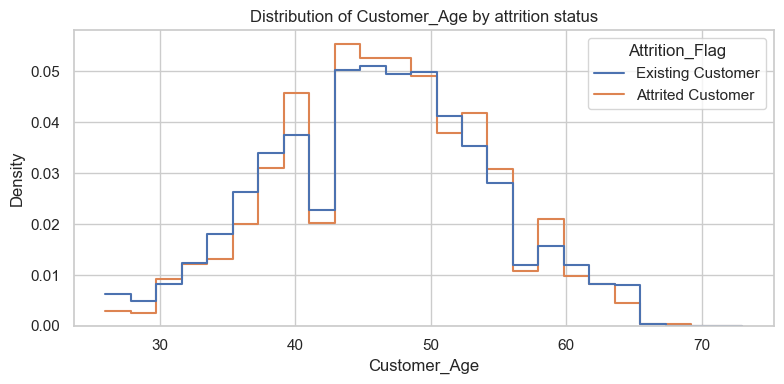

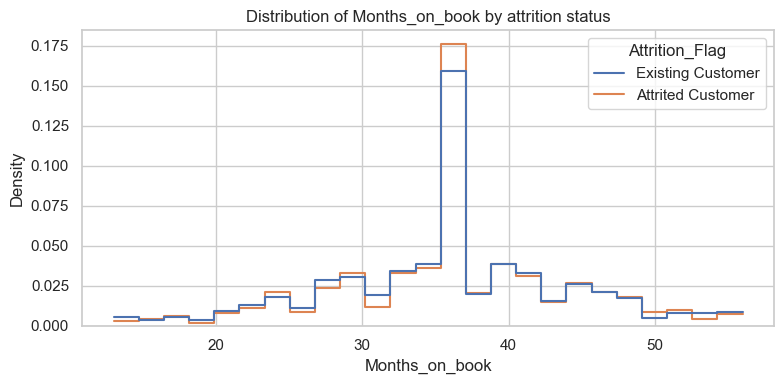

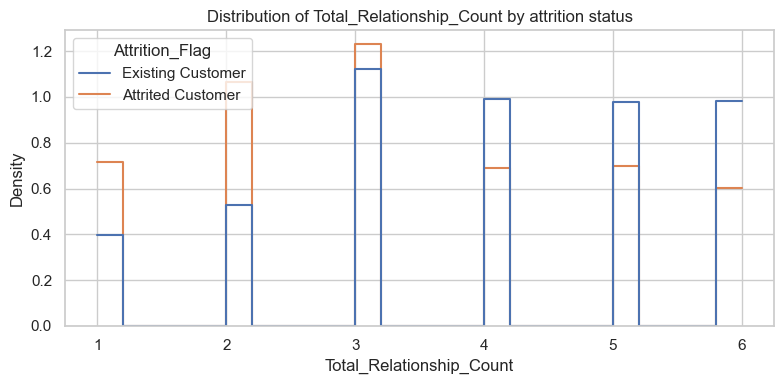

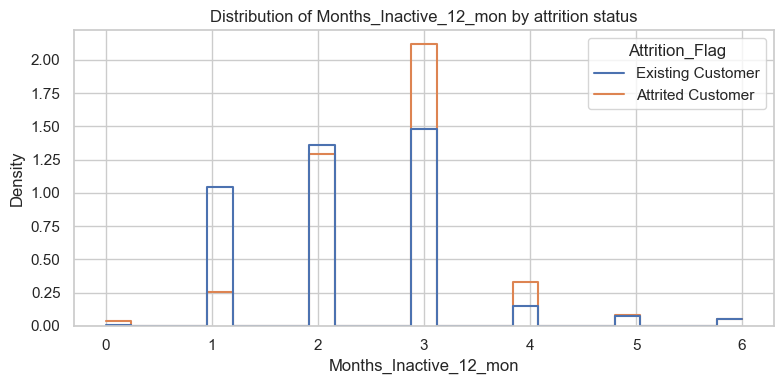

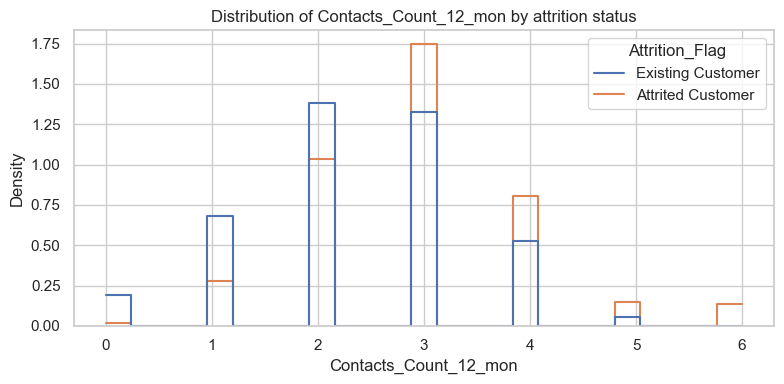

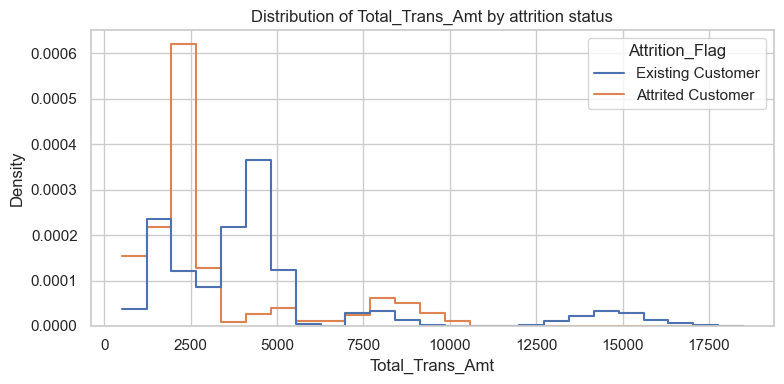

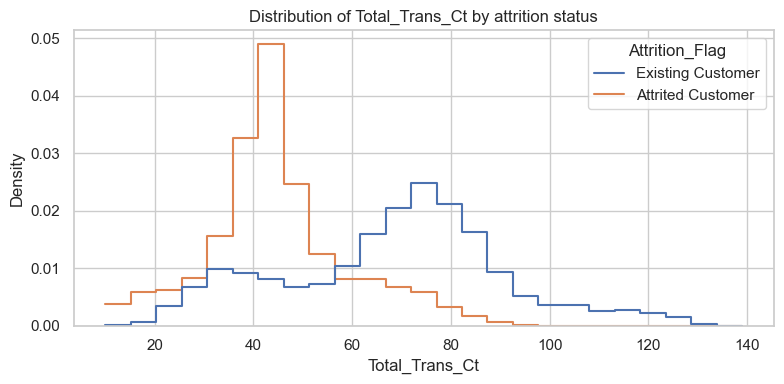

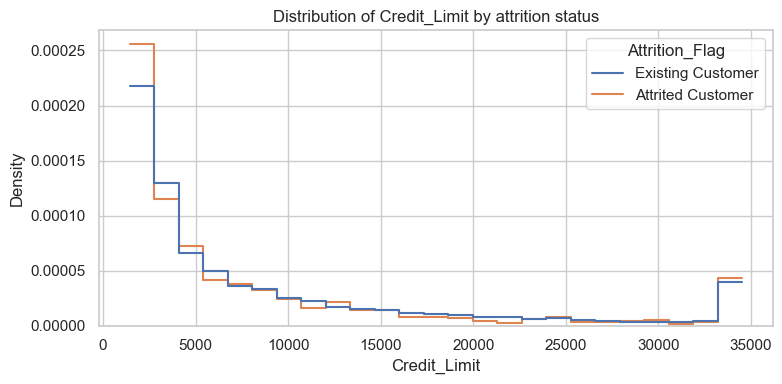

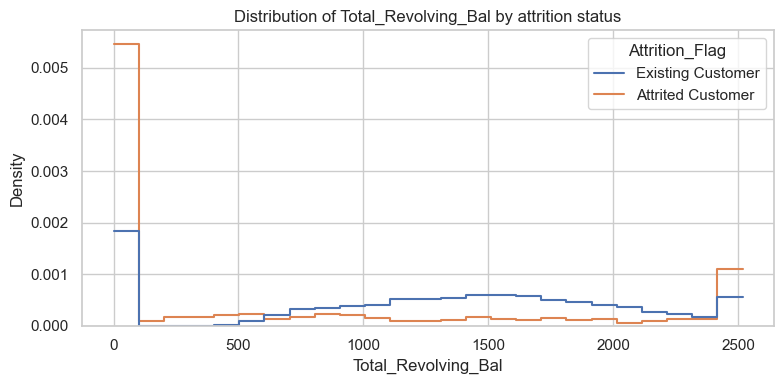

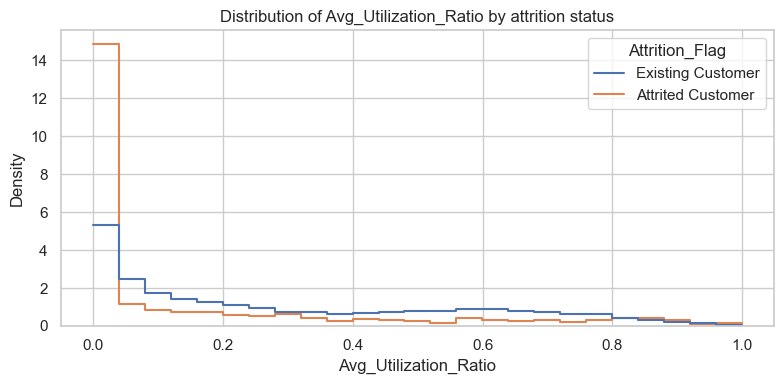

In [20]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(
        data=df, x=col, hue=target,
        stat='density', common_norm=False,
        bins=25, element='step', fill=False
    )
    plt.title(f'Distribution of {col} by attrition status')
    plt.tight_layout()
    plt.show()

**Summary — numerical distributions by target**

The class-wise distributions support the group-summary pattern: attrited customers tend to have fewer transactions and lower transaction amounts, while inactivity and contact counts tend to be higher. The distributions still overlap, so these variables should be treated as potentially informative predictors rather than rules that identify every attrited customer. `Credit_Limit` has a wide spread in both classes, and the difference between class averages is modest relative to that spread; by itself, it may be less discriminating than transaction activity. Interpret apparent differences alongside the unequal target-class sizes.

### 5.3 Categorical variables: attrition rate by category

For each categorical feature, calculate the proportion of customers in each category who are attrited. This is more informative than counts alone when category sizes differ.

The rate is calculated as the percentage of records in a category whose `Attrition_Flag` equals `Attrited Customer`. If the dataset uses different target labels, update `attrited_label` after checking the target value counts.

,Customer count,attrition_rate_pct
Gender,,
F,5358,17.36
M,4769,14.62


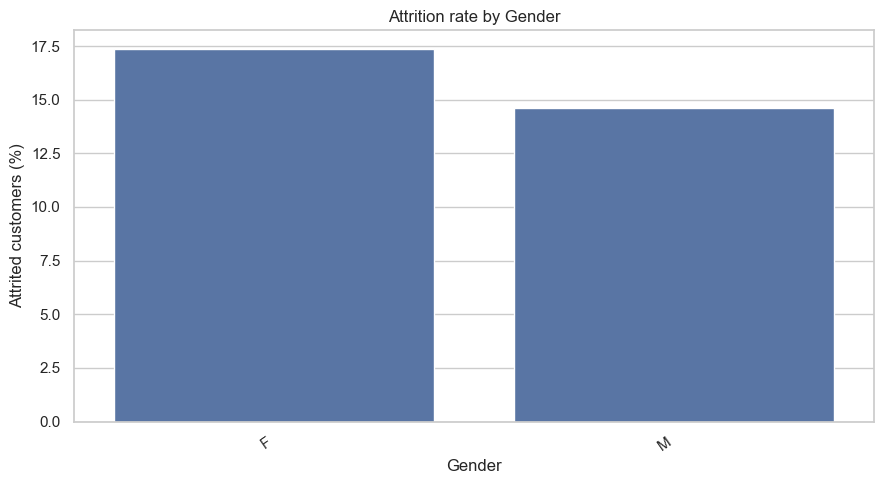

,Customer count,attrition_rate_pct
Education_Level,,
Doctorate,451,21.06
Post-Graduate,516,17.83
Unknown,1519,16.85
Uneducated,1487,15.94
Graduate,3128,15.57
College,1013,15.20
High School,2013,15.20


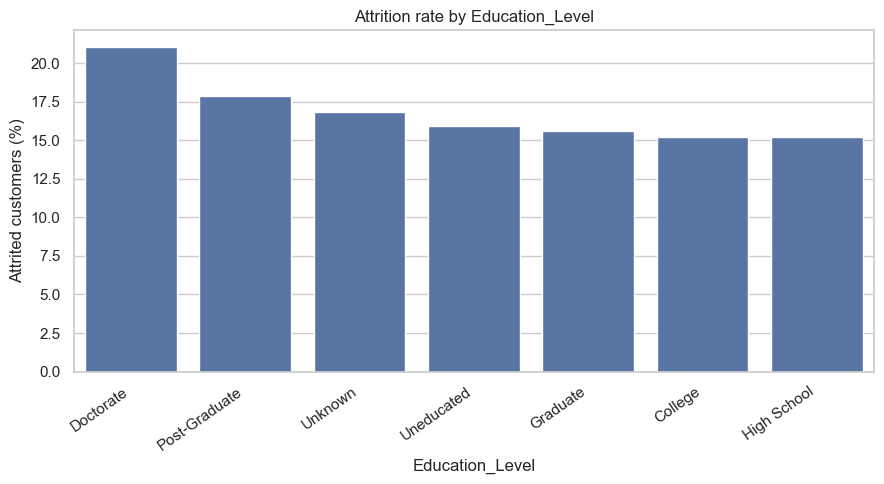

,Customer count,attrition_rate_pct
Marital_Status,,
Unknown,749,17.22
Single,3943,16.94
Divorced,748,16.18
Married,4687,15.13


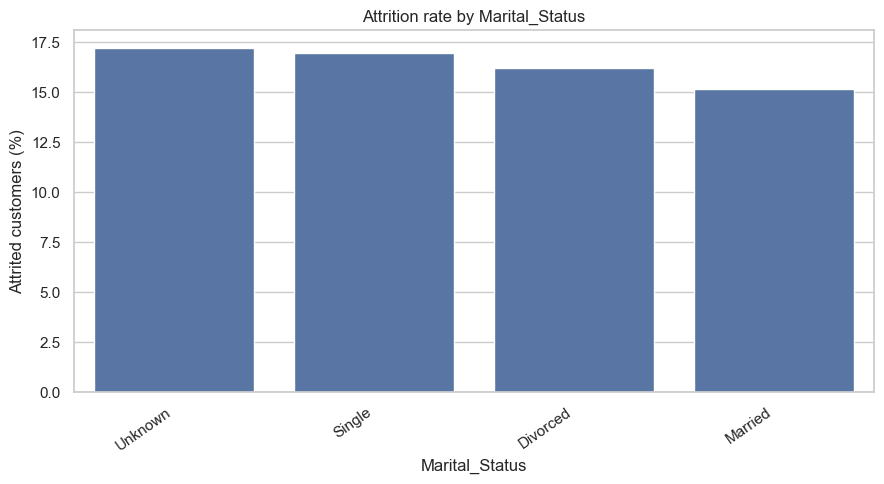

,Customer count,attrition_rate_pct
Income_Category,,
$120K +,727,17.33
Less than $40K,3561,17.19
Unknown,1112,16.82
$80K - $120K,1535,15.77
$40K - $60K,1790,15.14
$60K - $80K,1402,13.48


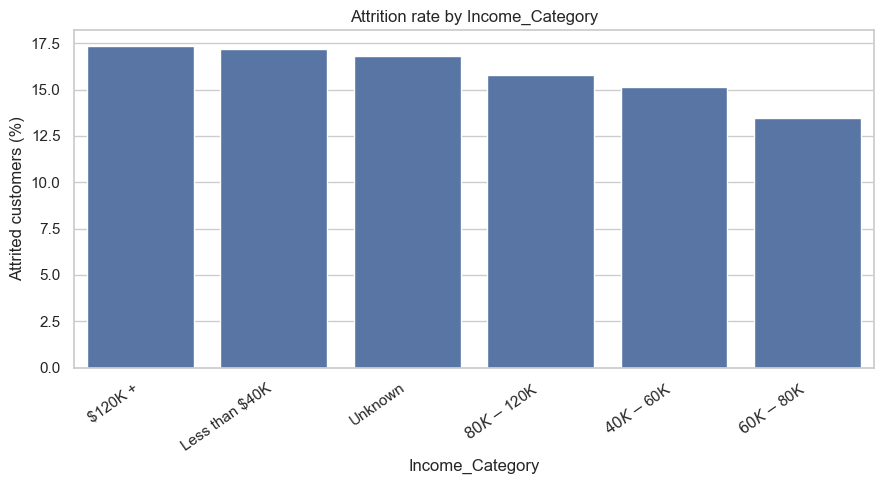

,Customer count,attrition_rate_pct
Card_Category,,
Platinum,20,25.00
Gold,116,18.10
Blue,9436,16.10
Silver,555,14.77


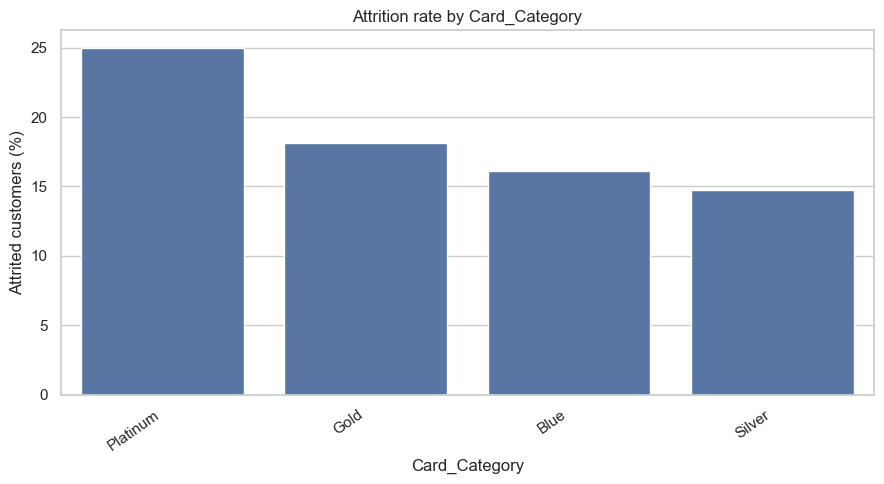

In [21]:
attrited_label = 'Attrited Customer'

if attrited_label not in df[target].astype(str).unique():
    print("Check target labels before interpreting attrition rates:", df[target].unique())
else:
    for col in categorical_cols:
        if col == target:
            continue

        rates = (
            df.assign(_is_attrited=(df[target] == attrited_label))
              .groupby(col, dropna=False)['_is_attrited']
              .agg(['mean', 'count'])
              .sort_values('mean', ascending=False)
        )
        rates['attrition_rate_pct'] = (rates['mean'] * 100).round(2)
        display(rates[['count', 'attrition_rate_pct']].rename(
            columns={'count': 'Customer count'}
        ))

        plt.figure(figsize=(9, 5))
        plot_data = rates.reset_index()
        sns.barplot(data=plot_data, x=col, y='attrition_rate_pct')
        plt.title(f'Attrition rate by {col}')
        plt.xlabel(col)
        plt.ylabel('Attrited customers (%)')
        plt.xticks(rotation=35, ha='right')
        plt.tight_layout()
        plt.show()

**Interpretation prompts**
- Which categories have higher observed attrition rates?
- Are those rates based on many customers or only a small group?
- Do any categories contain `Unknown` values, and how should these be treated?
- Are differences practically meaningful, or could they be influenced by small category counts?

**Summary — categorical attrition rates**

The category rates are generally fairly close, so categorical variables appear to offer more modest separation than some of the transaction and activity measures. In this dataset, the observed rate is higher for women than men (17.36% vs 14.62%). Education-level rates range from about 15.20% for College and High School to 21.06% for Doctorate, although the Doctorate category has only 451 customers. Marital-status rates range from 15.13% for Married customers to 17.22% for `Unknown`; income-category rates range from 13.48% for the $60K–$80K group to 17.33% for $120K+. Platinum cardholders show a 25% rate, but this category contains only **20 customers**, so that estimate is unstable and should not be overinterpreted. Always consider both the rate and its category count. `Unknown` rates should not be interpreted as a substantive demographic group.

### Section 5 summary

Overall, the strongest descriptive signals are associated with **transaction activity** (`Total_Trans_Ct`, `Total_Trans_Amt`) and **customer engagement** (`Months_Inactive_12_mon`, `Contacts_Count_12_mon`, `Total_Relationship_Count`). Attrited customers transact less frequently and for lower total amounts, are inactive for more months, contact the bank more often, and have fewer relationships on average. Credit utilisation and revolving balance also differ between the groups. Demographic and card-category differences are present but should be interpreted cautiously, especially for small categories. No one-variable plot establishes causation or guarantees predictive performance; these patterns should be tested with held-out data during modelling.

---

## 6. Relationships between explanatory variables

### 6.1 Correlation between numerical variables

A correlation heatmap can highlight numerical features that move together. Strong correlations may indicate overlapping information, but correlation alone does not determine which feature should be removed. The target is categorical, so it is not included in this numerical correlation matrix.

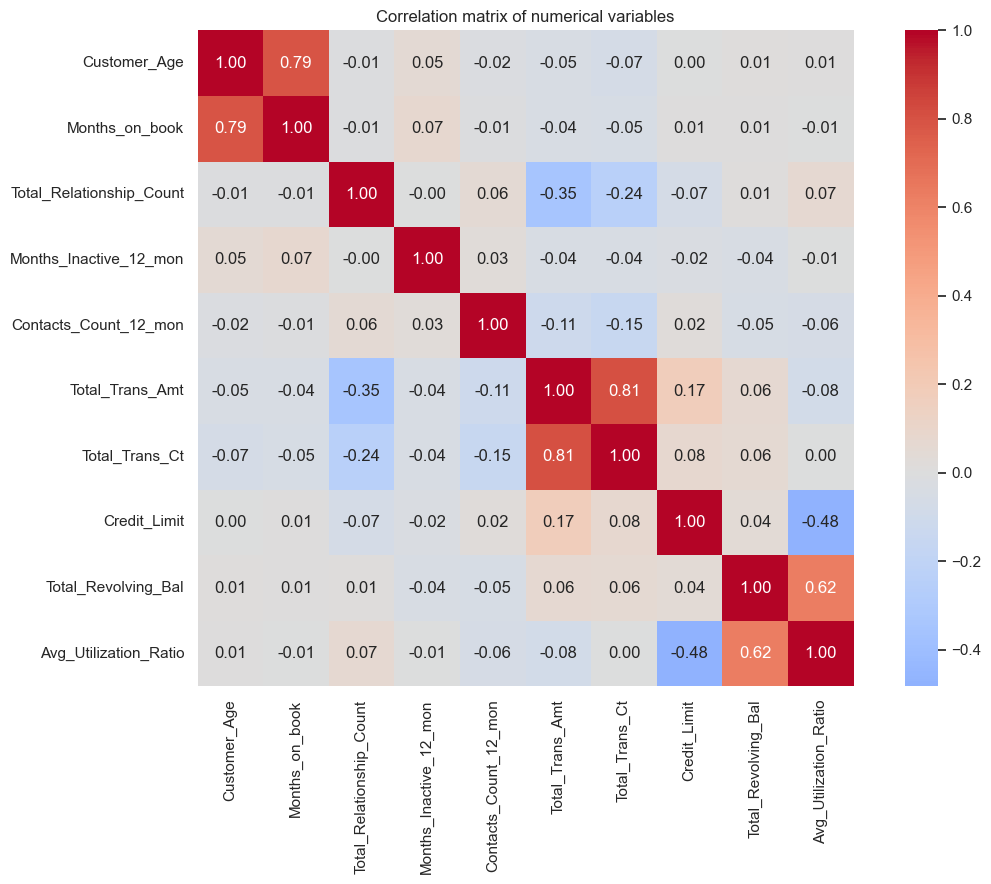

In [22]:
corr = df[numeric_cols].corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', square=True)
plt.title('Correlation matrix of numerical variables')
plt.tight_layout()
plt.show()

**How to read this plot.** Each cell is the Pearson correlation between two numerical variables: values near +1 indicate a strong positive linear relationship, values near -1 a strong negative linear relationship, and values near 0 little linear association. `Customer_Age` is the customer's age in years; `Months_on_book` is tenure in months. `Total_Relationship_Count` is the number of products/relationships held with the bank; `Months_Inactive_12_mon` counts inactive months in the last 12 months; `Contacts_Count_12_mon` counts contacts with the bank in the last 12 months. `Total_Trans_Amt` is total transaction amount, `Total_Trans_Ct` is transaction count, `Credit_Limit` is the assigned credit limit, `Total_Revolving_Bal` is the revolving balance, and `Avg_Utilization_Ratio` is average credit utilisation.

**Commentary.** The strongest positive correlations are between `Total_Trans_Amt` and `Total_Trans_Ct` (**r ≈ 0.81**), and between `Total_Revolving_Bal` and `Avg_Utilization_Ratio` (**r ≈ 0.62**). `Customer_Age` and `Months_on_book` are also strongly correlated (**r ≈ 0.79**), which is plausible because longer-lived customers may tend to be older. Credit limit and utilisation have a moderate negative correlation (**r ≈ -0.48**). These relationships indicate some overlap in information, but do not automatically mean that a feature should be removed. The correlation matrix is not a causal analysis and does not include the categorical target.

### 6.2 Selected activity and financial relationships

These scatterplots explore potentially meaningful pairs of variables. Colouring by attrition status may reveal whether combinations of customer activity and financial behaviour separate the target classes more clearly than either variable alone.

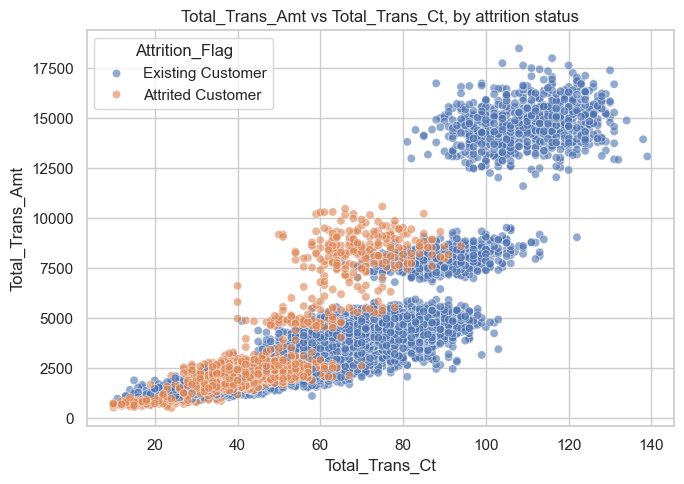

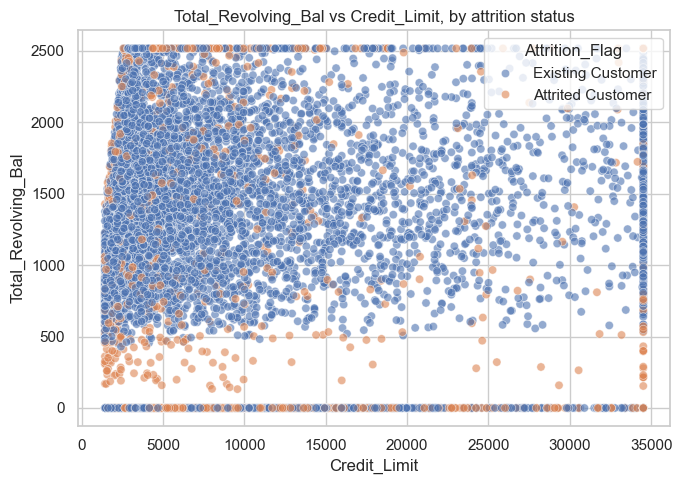

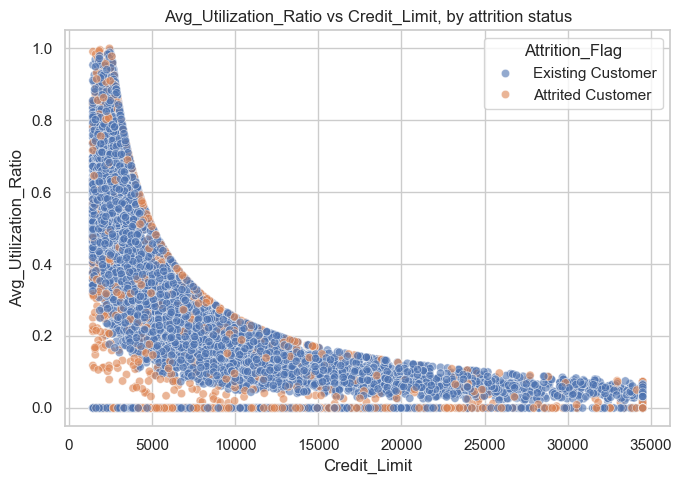

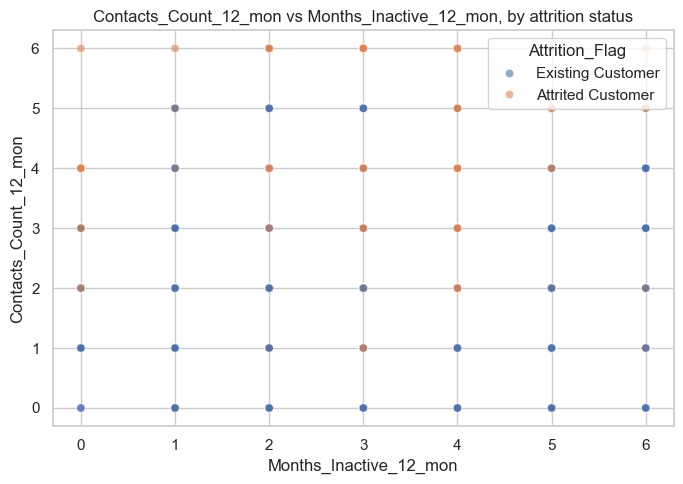

In [23]:
relationship_pairs = [
    ('Total_Trans_Ct', 'Total_Trans_Amt'),
    ('Credit_Limit', 'Total_Revolving_Bal'),
    ('Credit_Limit', 'Avg_Utilization_Ratio'),
    ('Months_Inactive_12_mon', 'Contacts_Count_12_mon')
]

for x_col, y_col in relationship_pairs:
    if x_col in df.columns and y_col in df.columns:
        plt.figure(figsize=(7, 5))
        sns.scatterplot(data=df, x=x_col, y=y_col, hue=target, alpha=0.6)
        plt.title(f'{y_col} vs {x_col}, by attrition status')
        plt.tight_layout()
        plt.show()

**Commentary on the selected scatterplots**

- **`Total_Trans_Ct` vs `Total_Trans_Amt`:** transaction count measures how often a customer transacted; transaction amount measures the total value of those transactions. The overall relationship is strongly positive, and attrited customers tend to cluster at lower counts and amounts. The two features are related but not identical: customers can make different-sized transactions.
- **`Credit_Limit` vs `Total_Revolving_Bal`:** credit limit is the customer's available credit limit; revolving balance is the balance carried on the revolving credit account. The overall linear correlation is weak (about **0.04**), so a higher limit does not necessarily correspond to a higher revolving balance in this sample.
- **`Credit_Limit` vs `Avg_Utilization_Ratio`:** utilisation expresses the proportion of available credit being used on average. The moderate negative correlation (about **-0.48**) suggests customers with higher credit limits often have lower utilisation ratios, although there is considerable variation.
- **`Months_Inactive_12_mon` vs `Contacts_Count_12_mon`:** these variables count months inactive in the last year and contacts with the bank in the last year, respectively. Their overall correlation is very weak (about **0.03**); the plot may still show class-level patterns, as attrited customers have higher averages on both measures, without the two predictors being strongly related to each other.

The colour represents `Attrition_Flag` (`Existing Customer` or `Attrited Customer`). Look for clusters and overlap rather than expecting a clean boundary. These plots are descriptive and cannot establish why customers leave.

---

## 7. Findings, limitations and conclusion

### Findings

- **Target distribution:** 8,500 customers (83.93%) are labelled `Existing Customer`; 1,627 (16.07%) are labelled `Attrited Customer`. The target is imbalanced, but the minority class still has 1,627 examples.
- **Numerical variables:** Transaction count and total transaction amount show some of the clearest differences between classes. Attrited customers have lower averages for both, alongside higher inactivity and contact counts and fewer bank relationships on average.
- **Categorical variables:** The observed attrition rate is higher for women than men and varies across education, marital-status, income and card categories. Differences are mostly modest. The Platinum-card rate is based on only 20 customers, so it is especially uncertain.
- **Relationships between predictors:** `Total_Trans_Ct` and `Total_Trans_Amt` are strongly correlated (r ≈ 0.81); `Customer_Age` and `Months_on_book` are also strongly correlated (r ≈ 0.79). Revolving balance and utilisation have a moderate positive correlation (r ≈ 0.62).
- **Data quality:** There are no null values or exact duplicate rows in the reduced dataset. `Unknown` appears in `Education_Level` (1,519 rows), `Marital_Status` (749 rows) and `Income_Category` (1,112 rows).
- **What to investigate during modelling:** Test how well transaction and engagement variables predict attrition on held-out data. Consider the correlation between related features and document how `Unknown` categories are handled. Use metrics that assess the minority class as well as overall performance.

### Limitations

- **Imbalanced target:** A model can achieve high accuracy by favouring the majority class. Evaluate attrition-class recall and precision, F1-score, a confusion matrix and balanced metrics; do not rely on accuracy alone.
- **Association is not causation:** Group differences and correlations do not show that a variable causes customers to leave. Other variables may contribute to the observed patterns.
- **Overlapping distributions:** Even variables with noticeable group differences do not perfectly separate existing and attrited customers. EDA alone cannot establish the best model or feature set.
- **Small categories:** Rates calculated from small groups, particularly Platinum cardholders, can fluctuate considerably and should not be treated as robust estimates.
- **Unknown values:** These entries may represent unreported or unavailable information. Their reason is not specified in the dataset, so their meaning cannot be inferred from this analysis alone.
- **Fairness and privacy:** Demographic and financial attributes warrant careful consideration. Any use in a churn model should be justified, privacy-conscious and evaluated for potential disparate impacts.

### Conclusion and next steps

This EDA identifies transaction behaviour and customer engagement as promising areas for further predictive investigation. Attrited customers in this dataset tend to make fewer transactions with lower total transaction amounts, report more inactive months and bank contacts, and hold fewer bank relationships on average. Some predictor pairs are correlated, so overlapping information should be considered during feature selection, but correlation alone is not a reason to discard a feature.

The dataset is large enough to proceed to a carefully evaluated classification exercise, although the attrited class is the minority. The next modelling stage should use a stratified train/test split, compare a suitable baseline with candidate classifiers, and report class-specific metrics. Decisions about `Unknown` categories, correlated predictors and any feature transformations should be documented and evaluated empirically. These are proposed modelling considerations, not decisions made by this EDA.